<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/claude/gracious-brown-4ybsmj/simple_model/step2_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Простая интерпретируемая модель. Шаг 2: понятные признаки

На шаге 1 мы получили таблицу: все старты транскрипции train-контигов и в 10 раз больше случайных позиций.
Теперь для каждой строки считаем **признаки**: числа, у каждого из которых есть биологический смысл.

План ноутбука:
1. **Где искать мотивы.** Для известных элементов промотора строим профиль: на каком расстоянии от старта мотив встречается
   чаще, чем в случайном месте генома. Так выбираем окно для каждого признака по данным, а не наугад.
2. **Сам старт (Initiator).** Учим матрицу весов (PWM) для букв −5..+5 и смотрим на неё как на логотип мотива.
3. **Мотивы, найденные по данным.** Ищем 6-меры, сильнее всего обогащённые около стартов, даже если мы их не знали заранее.
4. **Считаем все признаки** для 2.5 млн строк таблицы.
5. **Проверяем каждый признак по отдельности** на валидационных контигах: насколько он сам по себе отделяет старты
   от фона и связан ли с силой старта.

Модели здесь ещё нет, она будет на шаге 3. Всё, что выучено по данным (PWM, k-меры), выучено только на `fit`-контигах.

## 0. Настройки, данные, таблица шага 1

In [1]:
import os, sys, gzip, glob, json, hashlib, tarfile, time, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, roc_auc_score
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SPECIES = os.environ.get("EPIC_SPECIES", "jaNemVect1.1")
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
DATA_DIR = os.environ.get("EPIC_DATA_DIR", "/content/epic")
OUT_DIR = os.environ.get("EPIC_OUT_DIR", "/content/drive/MyDrive/epic_simple" if ON_COLAB else "/content/epic_simple")
BASE, FP = f"{DATA_DIR}/{SPECIES}", f"{DATA_DIR}/{SPECIES}/for_participants"

# модуль с признаками лежит рядом с ноутбуком в репозитории; в Colab скачиваем его оттуда
if not os.path.exists("features.py"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/Mitochondrion3000/epic-competiton/"
                               "claude/gracious-brown-4ybsmj/simple_model/features.py", "features.py")
import features as F

table = pd.read_parquet(f"{OUT_DIR}/{SPECIES}.step1_table.parquet")
meta = json.load(open(f"{OUT_DIR}/{SPECIES}.step1_meta.json"))
print(f"таблица шага 1: {len(table):,} строк, положительных {int(table.y.sum()):,}; val-контиги {meta['VAL_CONTIGS']}")

таблица шага 1: 2,493,128 строк, положительных 226,648; val-контиги ['NC_064042.1', 'NC_064040.1']


In [2]:
# Скачивание (если данных ещё нет на этой машине) и чтение генома: тот же код, что в шаге 1
def download_dataset(species, data_dir):
    if os.path.isdir(f"{data_dir}/{species}"): return
    import requests
    os.makedirs(data_dir, exist_ok=True)
    rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
    f = [x for x in rec["files"] if x["key"] == f"{species}.tgz"][0]
    dst, md5 = f"{data_dir}/{species}.tgz", hashlib.md5()
    with requests.get(f["links"]["self"], stream=True, timeout=120) as r, open(dst, "wb") as fh:
        r.raise_for_status()
        for chunk in tqdm(r.iter_content(1 << 22), total=f["size"] // (1 << 22) + 1, desc=f"скачиваю {species}"):
            fh.write(chunk); md5.update(chunk)
    assert md5.hexdigest() == f.get("checksum", "md5:").split(":")[-1], "MD5 не совпал"
    with tarfile.open(dst) as tf:
        try: tf.extractall(data_dir, filter="data")
        except TypeError: tf.extractall(data_dir)
    os.remove(dst)

CODE = np.full(256, 4, np.uint8)
for i, b in enumerate("ACGT"):
    CODE[ord(b)] = CODE[ord(b.lower())] = i

def read_genome(path, keep):
    seq, low, name, chunks = {}, {}, None, []
    def flush():
        if name in keep:
            raw = np.frombuffer(b"".join(chunks), np.uint8)
            seq[name], low[name] = CODE[raw], raw >= ord("a")
    with gzip.open(path, "rb") as fh:
        for line in fh:
            if line.startswith(b">"):
                flush(); name, chunks = line[1:].split()[0].decode(), []
            elif name in keep:
                chunks.append(line.rstrip())
    flush()
    return seq, low

download_dataset(SPECIES, DATA_DIR)
SEQ, LOW = read_genome(f"{BASE}/genome/genome.fa.gz", set(table.chrom))
print(f"геном: {len(SEQ)} контигов, {sum(map(len, SEQ.values())) / 1e6:.0f} Мб")

геном: 12 контигов, 217 Мб


## 1. Где относительно старта встречаются известные мотивы

Берём по 40 тыс. стартов и случайных позиций из `fit` и вырезаем окна −300..+300 по ходу транскрипции.
Для каждого смещения считаем, во сколько раз чаще мотив **начинается** там у стартов, чем у случайных позиций
(log2: 0 = как в фоне, +1 = вдвое чаще, −1 = вдвое реже). Отдельно смотрим на **сильные** старты (счёт ≥ 10).

Проверяемые мотивы взяты из учебников по промоторам. Буквы IUPAC: `W` = A/T, `R` = A/G, `Y` = C/T, `N` = любая.

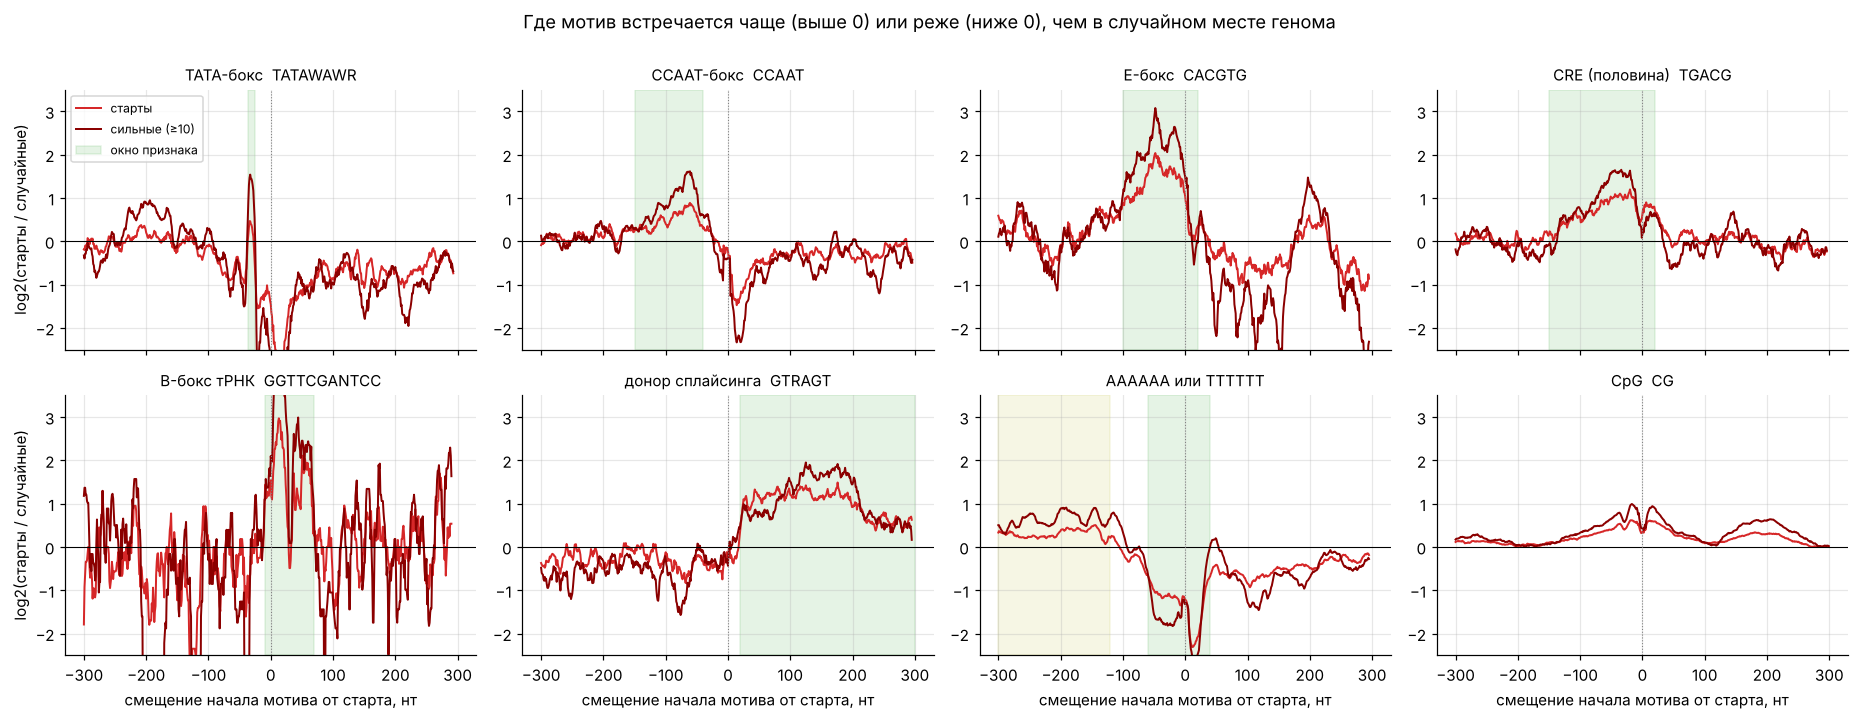

доля стартов, у которых есть хоть одно точное совпадение в окне признака:


  TATA-бокс          окно [-36, -25]:  старты 0.007 | сильные 0.014 | случайные 0.005


  CCAAT-бокс         окно [-150, -40]:  старты 0.137 | сильные 0.177 | случайные 0.100


  E-бокс             окно [-100, +20]:  старты 0.065 | сильные 0.106 | случайные 0.026


  CRE (половина)     окно [-150, +20]:  старты 0.168 | сильные 0.196 | случайные 0.102


  B-бокс тРНК        окно [-10, +70]:  старты 0.004 | сильные 0.011 | случайные 0.001


  донор сплайсинга   окно [+20, +300]:  старты 0.228 | сильные 0.260 | случайные 0.115


In [3]:
A, B = -300, 300
fit = table[table.split == "fit"]
smp = {"старты": fit[fit.y == 1].sample(40000, random_state=0),
       "сильные (≥10)": fit[fit.tot >= 10].sample(min(15000, int((fit.tot >= 10).sum())), random_state=0),
       "случайные": fit[fit.y == 0].sample(40000, random_state=0)}

def windows(df, a=A, b=B):
    # окна кодов (n x (b-a+1)) по ходу транскрипции
    off = np.arange(a, b + 1); out = np.full((len(df), len(off)), 4, np.uint8)
    for (c, st), d in df.groupby(["chrom", "strand"]):
        s = SEQ[c]; rows = df.index.get_indexer(d.index)
        g = d.pos.values[:, None] + (off if st == "+" else -off)[None, :]
        ok = (g >= 0) & (g < len(s)); gg = np.where(ok, g, 0)
        w = s[gg] if st == "+" else F.COMP[s[gg]]
        out[rows] = np.where(ok, w, 4)
    return out

for k in smp: smp[k] = smp[k].reset_index(drop=True)
WIN = {k: windows(d) for k, d in smp.items()}

def scan2d(W, motif, mm=0):
    # для каждой строки и каждого смещения: начинается ли там мотив (с <= mm несовпадений)
    m = len(motif); L = W.shape[1] - m + 1; sc = np.zeros((W.shape[0], L), np.int8)
    for k, ch in enumerate(motif):
        ok = np.zeros(5, bool); ok[["ACGT".index(x) for x in F.IUPAC[ch]]] = True
        sc += ok[W[:, k:k + L]]
    return sc >= m - mm

PROFILE = [("TATA-бокс", "TATAWAWR", 0, "tata"), ("CCAAT-бокс", "CCAAT", 0, "ccaat"), ("E-бокс", "CACGTG", 0, "ebox"),
           ("CRE (половина)", "TGACG", 0, "cre"), ("B-бокс тРНК", "GGTTCGANTCC", 1, "trna_bbox"),
           ("донор сплайсинга", "GTRAGT", 0, "splice_down"), ("AAAAAA или TTTTTT", None, 0, "polyAT_core"), ("CpG", "CG", 0, None)]

def smooth(x, k=11): return np.convolve(x, np.ones(k) / k, mode="same")

fig, axs = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True)
for ax, (title, motif, mm, feat) in zip(axs.ravel(), PROFILE):
    freq = {}
    for k, W in WIN.items():
        hit = (scan2d(W, "AAAAAA") | scan2d(W, "TTTTTT")) if motif is None else scan2d(W, motif, mm)
        freq[k] = smooth(hit.mean(0))
    x = np.arange(A, A + len(freq["старты"]))
    for k, col in (("старты", "tab:red"), ("сильные (≥10)", "darkred")):
        ax.plot(x, np.log2((freq[k] + 1e-6) / (freq["случайные"] + 1e-6)), color=col, lw=1.3, label=k)
    ax.axhline(0, color="k", lw=.7); ax.axvline(0, color="gray", lw=.7, ls=":")
    if feat is not None and feat in F.MOTIFS:
        a, b = F.MOTIFS[feat][2], F.MOTIFS[feat][3]
        ax.axvspan(a, b, color="tab:green", alpha=.12, label="окно признака")
    if motif is None: ax.axvspan(F.MOTIFS["polyAT_up"][2], F.MOTIFS["polyAT_up"][3], color="tab:olive", alpha=.12)
    ax.set_title(f"{title}" + (f"  {motif}" if motif else ""), fontsize=10)
    ax.set_ylim(-2.5, 3.5)
axs[0, 0].legend(fontsize=8, loc="upper left")
for ax in axs[1]: ax.set_xlabel("смещение начала мотива от старта, нт")
for ax in axs[:, 0]: ax.set_ylabel("log2(старты / случайные)")
plt.suptitle("Где мотив встречается чаще (выше 0) или реже (ниже 0), чем в случайном месте генома", y=1.0)
plt.tight_layout(); plt.show()
print("доля стартов, у которых есть хоть одно точное совпадение в окне признака:")
for title, motif, mm, feat in PROFILE:
    if feat is None or motif is None: continue
    a, b = F.MOTIFS[feat][2], F.MOTIFS[feat][3]
    r = {k: scan2d(W, motif, mm)[:, a - A:b - A + 1].any(1).mean() for k, W in WIN.items()}
    print(f"  {title:18s} окно [{a:+d}, {b:+d}]:  старты {r['старты']:.3f} | сильные {r['сильные (≥10)']:.3f} | случайные {r['случайные']:.3f}")

### Как читать профили
Зелёная полоса это окно, в котором признак считает вхождения мотива. Окна выбраны по этим же профилям: там, где красная
линия заметно выше (или ниже) нуля.

**Что видно на настоящих данных (*Nematostella*):**
* **TATA-бокс** встречается редко (точное совпадение в окне −36..−25 только у 0.7% стартов против 0.5% случайных), но там,
  где он есть, стоит ровно на −31..−30, как в учебнике. У сильных стартов пик выше. Признак честный, но редкий.
* **CCAAT-бокс** обогащён в −150..−40, особенно у сильных стартов (17.7% против 10%), а у самого старта и ниже по течению
  он встречается реже фона.
* **E-бокс (CACGTG)** самый яркий из известных мотивов: обогащение до 8 раз в −80..−20 у сильных стартов
  (10.6% против 2.6% у случайных позиций).
* **CRE (TGACG)** обогащён в −150..0.
* **B-бокс тРНК** даёт огромный пик сразу за стартом, но таких стартов мало (0.4%). Это отдельный класс генов (РНК-полимераза III).
* **Донор сплайсинга (GTRAGT)** обогащён в +20..+300, то есть вскоре после старта часто начинается интрон. Это признак
  «здесь начинается ген, а не случайный шум»: у 23% стартов против 11.5% фона.
* **Поли-A/T** сильно обеднены от −100 до +40 (у стартов в 2–4 раза реже) и слегка обогащены дальше −120. Так выглядит
  промотор без нуклеосом в окружении AT-богатой ДНК.
* **CpG** обогащён вокруг старта и вторым горбом на +150..+250.

## 2. Сам старт: матрица весов Initiator

Для букв на смещениях −5..+5 считаем частоту у стартов (`fit`) и делим на фоновую частоту буквы в геноме. log2 этого
отношения и есть вес: положительный, если буква на этом месте у стартов встречается чаще фона. Признак `inr_pwm` это
сумма весов по 11 позициям, то есть «насколько окрестность похожа на типичный старт».

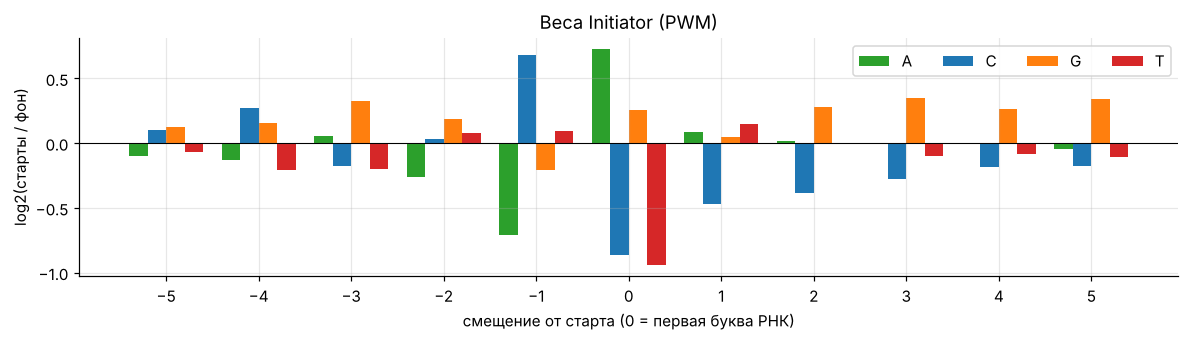

самая «стартовая» буква на каждом месте (−5..+5): GCGGC[A]TGGGG
фон генома A/C/G/T: [0.296 0.204 0.203 0.296]


In [4]:
bg = np.bincount(np.concatenate([SEQ[c][::97] for c in SEQ]), minlength=5)[:4]
bg = bg / bg.sum()
pos_fit = fit[fit.y == 1]
PWM = F.fit_pwm(windows(pos_fit, F.PWM_A, F.PWM_B), bg)

fig, ax = plt.subplots(figsize=(11, 3.2))
offs = np.arange(F.PWM_A, F.PWM_B + 1); w = 0.2
for k, (b, col) in enumerate(zip("ACGT", ["tab:green", "tab:blue", "tab:orange", "tab:red"])):
    ax.bar(offs + (k - 1.5) * w, PWM[k], w, color=col, label=b)
ax.axhline(0, color="k", lw=.7); ax.set_xticks(offs)
ax.set(xlabel="смещение от старта (0 = первая буква РНК)", ylabel="log2(старты / фон)", title="Веса Initiator (PWM)")
ax.legend(ncol=4)
plt.tight_layout(); plt.show()
best = "".join("ACGT"[i] for i in PWM[:4].argmax(0))
print("самая «стартовая» буква на каждом месте (−5..+5):", best[:5] + "[" + best[5] + "]" + best[6:])
print("фон генома A/C/G/T:", np.round(bg, 3))

**Как читать.** Самый сильный сигнал на позициях −1 и 0: на −1 чаще `C` (и реже `A`), на 0 чаще `A`, почти никогда `C`
или `T`. Это и есть мотив Initiator `C[A]`: РНК начинается с пурина, перед которым стоит пиримидин. Ниже старта
(+1..+5) слабо обогащено `G`: начало РНК у этого вида немного GC-богаче. Сам по себе Inr короткий и встречается в геноме
на каждом шагу, поэтому даже лучший его вариант даёт лишь умеренное обогащение (см. раздел 5).

## 3. Мотивы, найденные по данным

Известные мотивы покрывают не всё. Поэтому перебираем все 4096 вариантов 6-меров и для каждого считаем, у какой доли
стартов и у какой доли случайных позиций он встречается в окне −60..+20 (там, где сидит ядро промотора). Берём самые
обогащённые, но только достаточно частые (≥ 1.5% стартов), и выкидываем почти-дубликаты (если 6-мер делит 5 букв подряд
с уже выбранным). Каждый выбранный 6-мер становится признаком «сколько раз он встречается в окне».

In [5]:
KA, KB, K, N_KMERS = -60, 20, 6, 8

def kmer_presence(W):
    L = W.shape[1] - K + 1
    code = np.zeros((W.shape[0], L), np.int64); bad = np.zeros((W.shape[0], L), bool)
    for j in range(K):
        code = code * 4 + np.minimum(W[:, j:j + L], 3); bad |= W[:, j:j + L] > 3
    pres = np.zeros((W.shape[0], 4 ** K), bool)
    r = np.repeat(np.arange(W.shape[0]), L); c = code.ravel(); ok = ~bad.ravel()
    pres[r[ok], c[ok]] = True
    return pres.mean(0)

kname = lambda i: "".join("ACGT"[(i >> (2 * (K - 1 - j))) & 3] for j in range(K))
sl = slice(KA - A, KB - A + 1)
fp, fn, fs = (kmer_presence(WIN[k][:, sl]) for k in ("старты", "случайные", "сильные (≥10)"))
enr = np.log2((fp + 1e-3) / (fn + 1e-3))
order = np.argsort(-np.where(fp >= 0.015, enr, -np.inf))
known = {"CCAAT", "CACGTG", "TGACG", "TATAAA"}
chosen = []
for i in order:
    s = kname(i)
    subs = {s[j:j + 5] for j in range(2)}
    if any(subs & {c[j:j + 5] for j in range(2)} for c in chosen): continue
    if any(m in s for m in known): continue                    # уже есть среди известных мотивов
    chosen.append(s)
    if len(chosen) == N_KMERS: break

idx = {kname(j): j for j in range(4 ** K)}
kt = pd.DataFrame({"6-мер": chosen, "доля стартов": [fp[idx[c]] for c in chosen], "доля сильных": [fs[idx[c]] for c in chosen],
                   "доля случайных": [fn[idx[c]] for c in chosen], "обогащение, раз": [fp[idx[c]] / fn[idx[c]] for c in chosen]})
display(kt.style.format({c: "{:.3f}" for c in kt.columns[1:4]} | {"обогащение, раз": "{:.1f}"}))
PARAMS = {"pwm": PWM, "kmers": [(c, KA, KB) for c in chosen]}

,6-мер,доля стартов,доля сильных,доля случайных,"обогащение, раз"
0,TGGCGG,0.053,0.106,0.011,4.7
1,CAGCGG,0.032,0.054,0.009,3.6
2,CCTGTG,0.062,0.100,0.019,3.3
3,GCGGAC,0.020,0.041,0.006,3.5
4,CCGCTG,0.031,0.048,0.009,3.2
5,CATGCG,0.032,0.056,0.012,2.7
6,CGTGAC,0.036,0.053,0.014,2.6
7,GCGGGC,0.016,0.024,0.006,2.7


**Что нашлось.** Все отобранные 6-меры богаты CG: `TGGCGG`, `CAGCGG`, `GCGGAC`, `CCGCTG`, `CATGCG`, `GCGGGC`.
Похоже, это части GC-богатых сайтов факторов транскрипции (например, `GCGGGC` напоминает сайт E2F/Sp, а `CGTGAC` включает
половину CRE и мотив `GTGAC`), а также общий признак CpG-островка.
Строгое название каждого k-мера требует сравнения с базой мотивов (JASPAR), но для модели достаточно, что они
читаются как «последовательность X рядом со стартом».

## 4. Считаем все признаки для таблицы

Для каждого контига строим дорожки (значение признака в каждой позиции, на обеих цепях) и берём из них значения
в строках таблицы. Тот же код на шаге 4 посчитает признаки для всех 72 млн позиций теста. Занимает около 10 минут.

In [6]:
t0 = time.time()
cols = None
parts = []
for c, d in tqdm(table.groupby("chrom", sort=False), desc="контиги", total=table.chrom.nunique()):
    f = F.contig_features(SEQ[c], LOW[c], d.pos.values, d.strand.values, PARAMS)
    parts.append(pd.DataFrame(f, index=d.index))
feat = pd.concat(parts).loc[table.index]
FEATURES = list(feat.columns)
data = pd.concat([table, feat], axis=1)
print(f"{len(FEATURES)} признаков за {(time.time() - t0) / 60:.1f} мин")

json.dump({"pwm": PWM.tolist(), "kmers": PARAMS["kmers"], "features": FEATURES},
          open(f"{OUT_DIR}/{SPECIES}.step2_params.json", "w"))
data.to_parquet(f"{OUT_DIR}/{SPECIES}.step2_features.parquet", index=False)
data[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(3)

27 признаков за 6.9 мин


,mean,std,min,50%,max
inr_pwm,-0.320,1.073,-3.856,-0.334,3.607
inr_yr,0.258,0.438,0.000,0.000,1.000
div_inr,2.328,0.312,-0.865,2.310,3.710
tata,0.007,0.104,0.000,0.000,6.000
ccaat,0.110,0.340,0.000,0.000,11.000
ebox,0.032,0.190,0.000,0.000,6.000
cre,0.122,0.372,0.000,0.000,15.000
trna_abox,0.019,0.138,0.000,0.000,3.000
trna_bbox,0.002,0.045,0.000,0.000,2.000
splice_down,0.140,0.446,0.000,0.000,70.000


## 5. Насколько полезен каждый признак сам по себе

Считаем на валидационных контигах (их не видели ни PWM, ни отбор k-меров), по каждому признаку отдельно:
* **AUROC**: вероятность, что у случайного старта значение признака больше, чем у случайной фоновой позиции.
  0.5 = признак бесполезен; ниже 0.5 = признак работает «наоборот» (у стартов он меньше), это тоже полезно, просто знак обратный.
* **AUPRC, во сколько раз лучше случайного**: та же метрика, что в соревновании, если бы мы ранжировали весь геном только
  по этому признаку. Строки отрицательных взвешены колонкой `w`, поэтому оценка соответствует полному геному.
* **Spearman с силой старта**: среди стартов, помогает ли признак угадать, сколько прочтений (вторая метрика соревнования).

In [7]:
val = data[data.split == "val"]
rows = []
for f in FEATURES:
    x = val[f].values.astype(float)
    auc = roc_auc_score(val.y, x)
    sgn = 1 if auc >= 0.5 else -1
    ap = average_precision_score(val.y, sgn * x, sample_weight=val.w)
    pos = val[val.y == 1]
    rho = spearmanr(pos[f], pos.tot).correlation if pos[f].nunique() > 1 else 0.0
    grp = next(g for g, fs in F.GROUPS.items() if f in fs) if any(f in fs for fs in F.GROUPS.values()) else "найденные k-меры"
    rows.append({"признак": f, "группа": grp, "AUROC": auc, "направление": "↑ у стартов больше" if sgn > 0 else "↓ у стартов меньше",
                 "AUPRC / случайный": ap / meta["RATE"], "Spearman с силой": rho,
                 "что это": F.DESCRIPTIONS.get(f, f"6-мер {f[5:]} в окне [{KA}, {KB}]")})
uni = pd.DataFrame(rows).sort_values("AUROC", key=lambda s: -abs(s - 0.5)).reset_index(drop=True)
display(uni.style.format({"AUROC": "{:.3f}", "AUPRC / случайный": "{:.2f}", "Spearman с силой": "{:+.3f}"})
        .bar(subset=["AUROC"], align=0.5, color=["#5fa2dd", "#e3735e"]))

,признак,группа,AUROC,направление,AUPRC / случайный,Spearman с силой,что это
0,inr_pwm,сам старт,0.695,↑ у стартов больше,2.30,+0.152,похожесть на Initiator: сумма log2(частота у стартов / фон) по буквам −5..+5
1,gc_core,состав,0.662,↑ у стартов больше,1.49,+0.050,доля G+C вокруг старта
2,rep_core,повторы,0.356,↓ у стартов меньше,1.48,+0.050,доля повторов (строчных букв) вокруг
3,inr_yr,сам старт,0.619,↑ у стартов больше,1.48,+0.179,классический Inr: пиримидин (C/T) на −1 и пурин (A/G) на 0
4,cpg_core,состав,0.592,↑ у стартов больше,1.22,+0.144,CpG наблюдаемое/ожидаемое вокруг старта (CpG-островок)
5,cpg_down,состав,0.581,↑ у стартов больше,1.23,+0.139,CpG наблюдаемое/ожидаемое ниже старта
6,splice_down,структура гена,0.560,↑ у стартов больше,1.25,+0.036,донорный сайт сплайсинга ниже старта: конец первого экзона
7,rep_here,повторы,0.440,↓ у стартов меньше,1.14,+0.038,сам старт внутри повтора
8,polyAT_core,поли-A/T,0.443,↓ у стартов меньше,1.14,-0.008,участки AAAAAA/TTTTTT у самого старта (у стартов обеднены)
9,gc_down,состав,0.532,↑ у стартов больше,1.02,+0.001,доля G+C ниже старта (тело РНК)


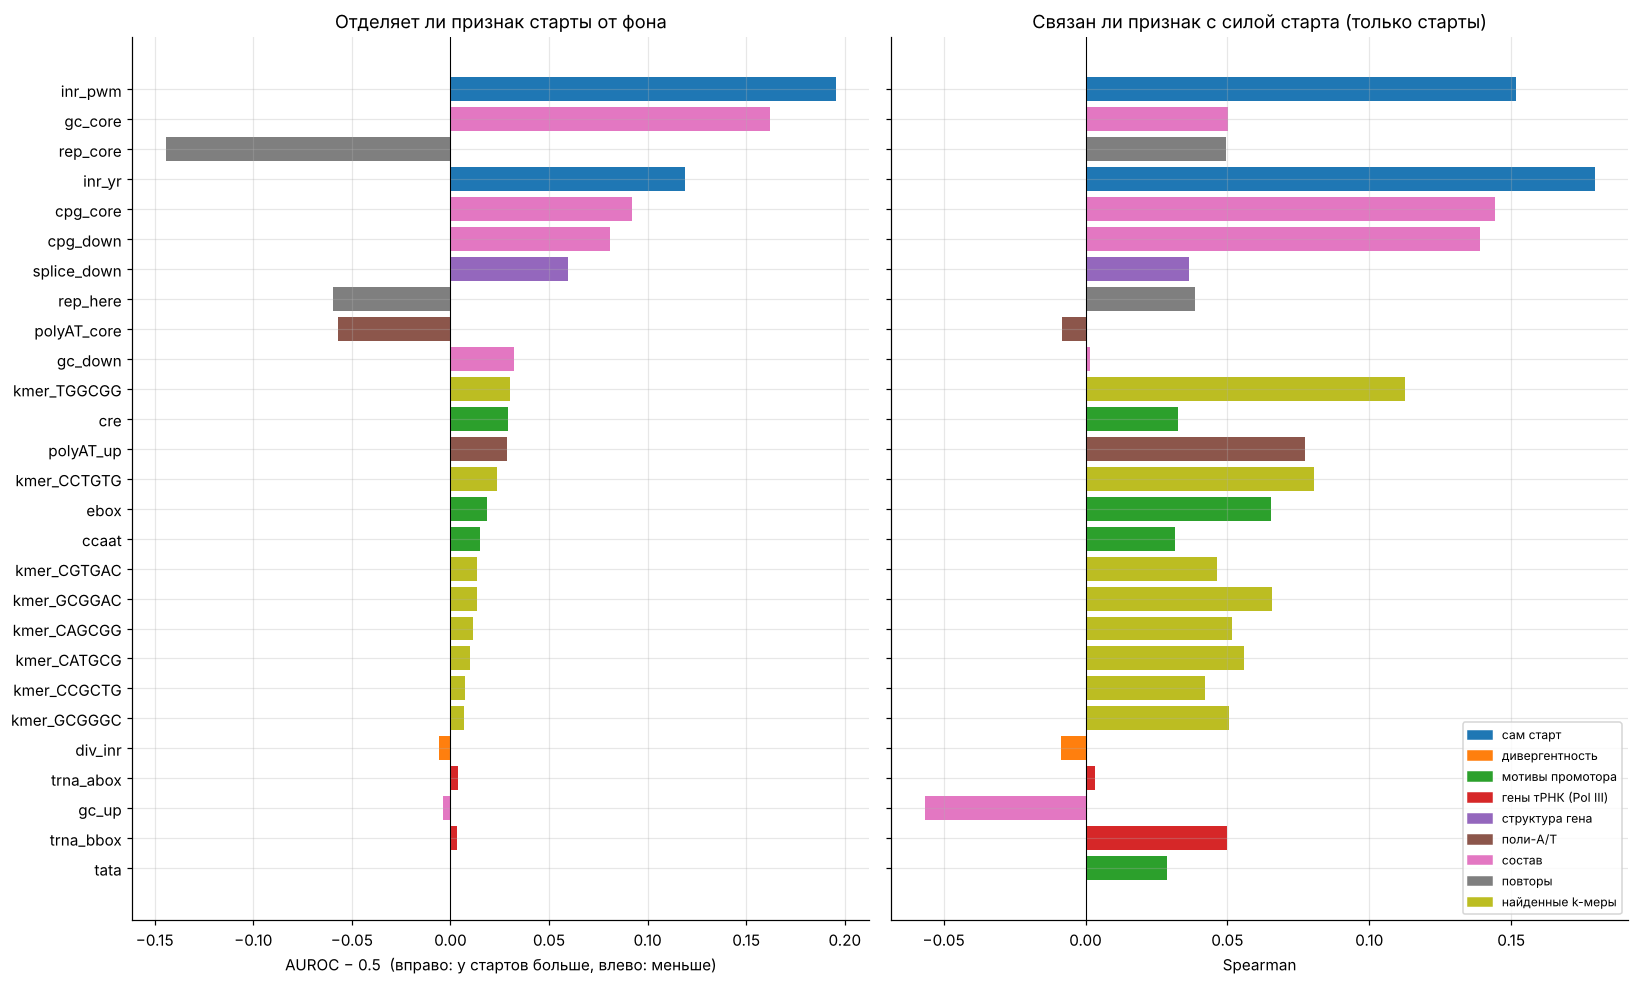

In [8]:
gcol = {g: c for g, c in zip(list(F.GROUPS) + ["найденные k-меры"], plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2])}
u = uni.iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 0.28 * len(u) + 1.5), sharey=True)
ax[0].barh(u.признак, u.AUROC - 0.5, color=[gcol[g] for g in u.группа])
ax[0].axvline(0, color="k", lw=.7); ax[0].set(xlabel="AUROC − 0.5  (вправо: у стартов больше, влево: меньше)",
                                             title="Отделяет ли признак старты от фона")
ax[1].barh(u.признак, u["Spearman с силой"], color=[gcol[g] for g in u.группа])
ax[1].axvline(0, color="k", lw=.7); ax[1].set(xlabel="Spearman", title="Связан ли признак с силой старта (только старты)")
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=c, label=g) for g, c in gcol.items()], fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### Как признак меняет шанс старта

Для шести самых сильных признаков делим валидационные позиции на группы по значению признака и считаем, во сколько раз
доля стартов в группе выше средней (с учётом весов `w`, то есть как в полном геноме). Это и есть «интерпретация словами»:
например, «при GC вокруг старта выше 0.5 шанс старта в N раз выше среднего».

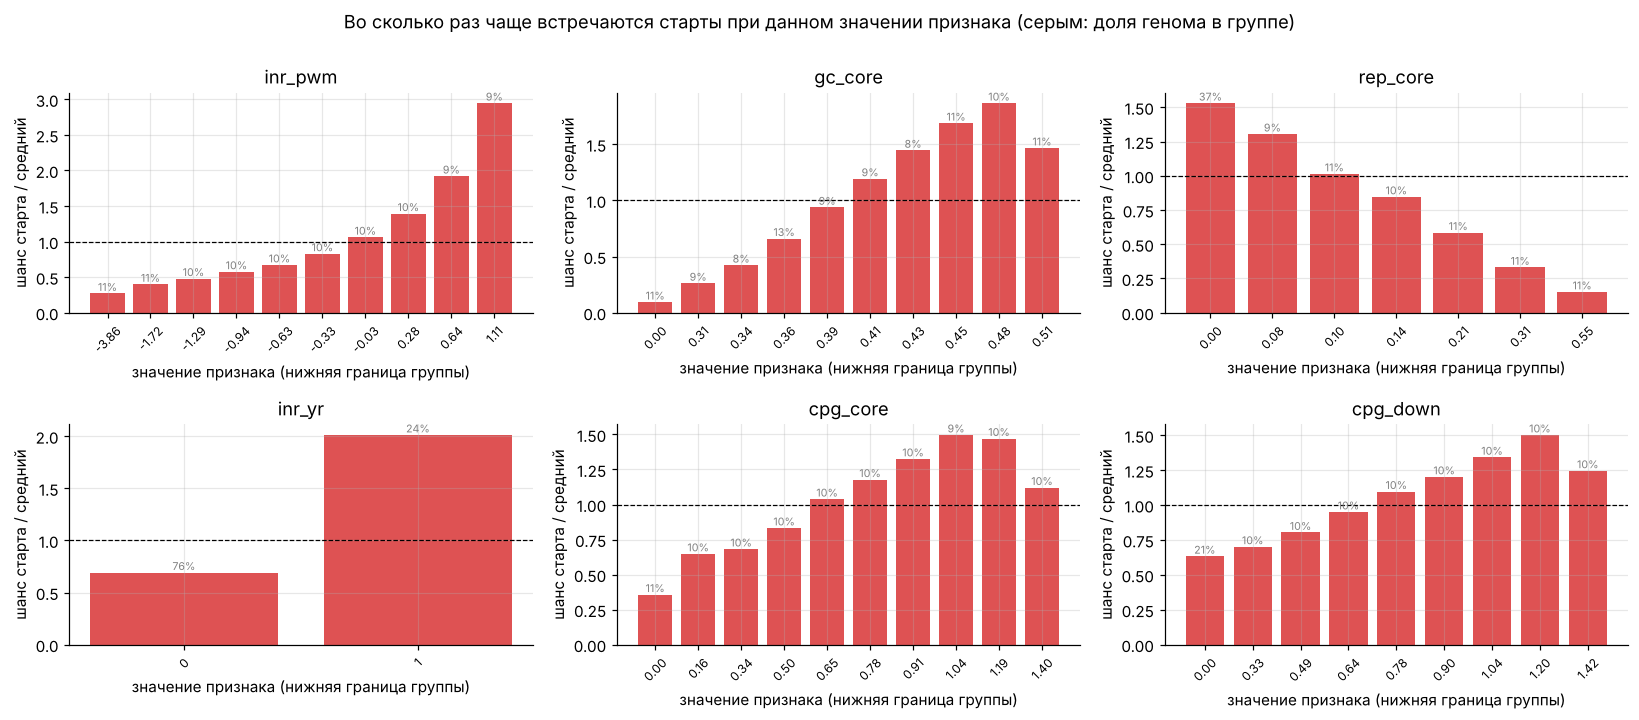

In [9]:
top = uni.признак.head(6).tolist()
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, f in zip(axs.ravel(), top):
    x = val[f].values
    if np.unique(x).size <= 6:
        bins = np.unique(x); grp = np.searchsorted(bins, x); labels = [f"{b:g}" for b in bins]
    else:
        qs = np.unique(np.quantile(x, np.linspace(0, 1, 11)))
        grp = np.clip(np.searchsorted(qs, x, side="right") - 1, 0, len(qs) - 2); labels = [f"{qs[i]:.2f}" for i in range(len(qs) - 1)]
    d = pd.DataFrame({"g": grp, "y": val.y.values, "w": np.where(val.y.values == 1, 1.0, val.w.values)})
    rate = d.groupby("g").apply(lambda t: (t.y * t.w).sum() / t.w.sum(), include_groups=False)
    share = d.groupby("g").w.sum() / d.w.sum()
    ax.bar(range(len(rate)), rate.values / meta["RATE"], color="tab:red", alpha=.8)
    ax.axhline(1, color="k", lw=.8, ls="--")
    ax.set_xticks(range(len(rate)), [labels[i] for i in rate.index], rotation=45, fontsize=8)
    for i, (r, s) in enumerate(zip(rate.values / meta["RATE"], share.values)):
        ax.text(i, r, f"{s:.0%}", ha="center", va="bottom", fontsize=7, color="gray")
    ax.set(title=f"{f}", ylabel="шанс старта / средний", xlabel="значение признака (нижняя граница группы)")
plt.suptitle("Во сколько раз чаще встречаются старты при данном значении признака (серым: доля генома в группе)", y=1.0)
plt.tight_layout(); plt.show()

### Насколько признаки дублируют друг друга
Если два признака сильно коррелируют, модель может поделить вес между ними произвольно, и читать веса станет труднее.

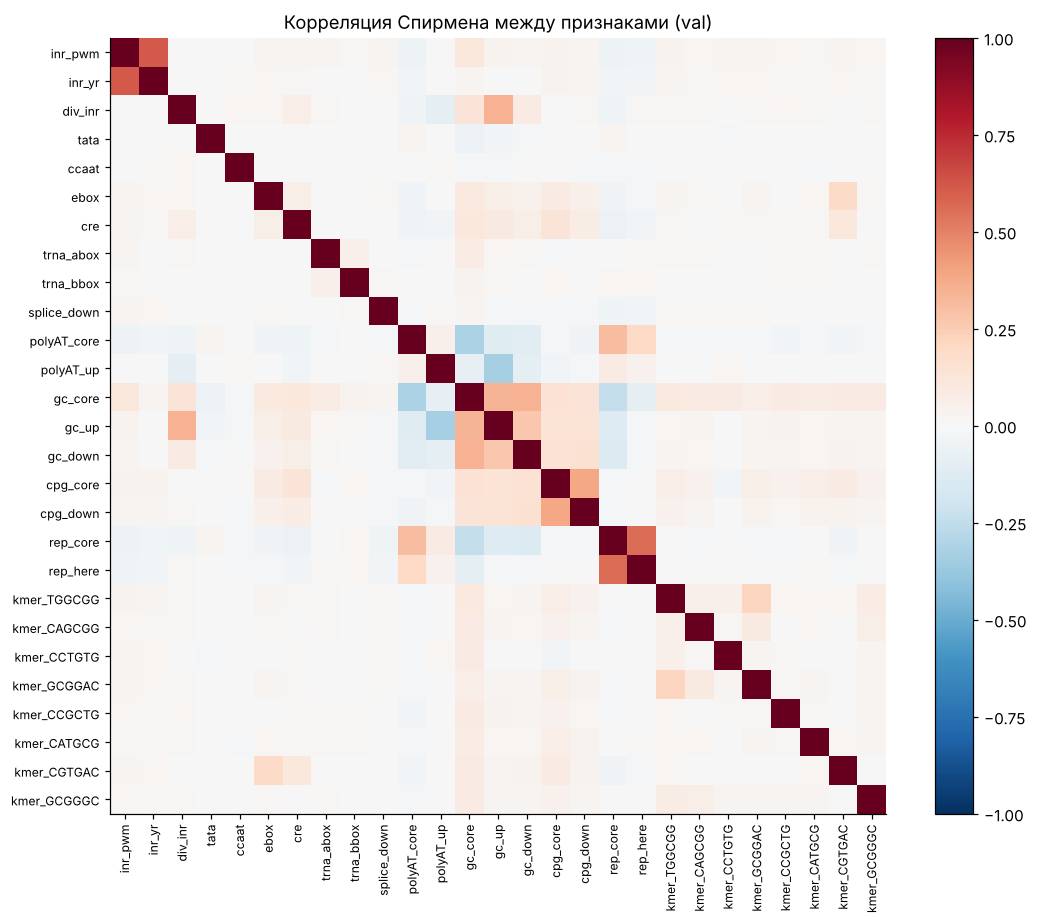

самые связанные пары:
inr_pwm   inr_yr      0.62
rep_core  rep_here    0.56
cpg_core  cpg_down    0.39
div_inr   gc_up       0.35
gc_core   gc_down     0.35
          gc_up       0.34


In [10]:
cm = val[FEATURES].sample(200000, random_state=0).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8); ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
ax.grid(False); plt.colorbar(im, fraction=0.04); ax.set_title("Корреляция Спирмена между признаками (val)")
plt.tight_layout(); plt.show()
pairs = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack()
print("самые связанные пары:"); print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

## Итог шага 2

**Что получилось.** 27 признаков, у каждого есть биологическое объяснение. Таблица с признаками сохранена для шага 3.

**Главное из раздела 5 (по одному признаку на валидации):**

| признак | AUROC | AUPRC / случайный | Spearman с силой | словами |
|---|---|---|---|---|
| `inr_pwm` | 0.70 | 2.3× | +0.15 | позиция похожа на Initiator `C[A]`: у лучших 10% шанс старта в 3 раза выше среднего |
| `gc_core` | 0.66 | 1.5× | +0.05 | чем больше G+C в ±50 нт, тем чаще старт (до 1.9 раза) |
| `rep_core` | 0.36 ↓ | 1.5× | +0.05 | в повторах старты почти не встречаются: при доле повторов > 55% шанс в 6 раз ниже |
| `inr_yr` | 0.62 | 1.5× | +0.18 | пиримидин-пурин на −1/0: шанс ×2 |
| `cpg_core`, `cpg_down` | 0.59 | 1.2× | +0.14 | CpG вокруг старта и ниже по течению |
| `splice_down` | 0.56 | 1.25× | +0.04 | ниже старта есть начало интрона |

**Что не сработало.** `div_inr` (дивергентный старт на другой цепи) бесполезен в нынешнем виде: максимум PWM по окну
в 250 нт почти у всех позиций одинаково высокий, потому что `CA` встречается везде. `tata`, `trna_abox`, `trna_bbox` почти
не меняют AUROC, но они редкие. Их ценность может проявиться для **сильных** стартов и в сочетании с другими признаками,
это проверим на шаге 3.

**Важная честная оценка.** Каждый признак по отдельности слабый: лучший даёт AUPRC в 2.3 раза выше случайного,
а большая CNN даёт примерно в 180 раз выше. Сильным должно стать сочетание признаков, и это задача шага 3.
Там же посмотрим, чего простой модели не хватает по сравнению с CNN.